# Stroke Prediction

## Intro

The task is to create a machine learning model, which could predict if the patient is likely to get a stroke - being able to determine which patients have high stroke risk will allow the doctors to advise them and their families on how to act in case of an emergency.

# About Dataset

This dataset is used to predict whether a patient is likely to get stroke based on the input parameters like gender, age, various diseases, and smoking status. Each row in the data provides relavant information about the patient.

Attribute Information:

1. id: unique identifier
2. gender: "Male", "Female" or "Other"
3. age: age of the patient
4. hypertension: 0 if the patient doesn't have hypertension, 1 if the patient has hypertension
5. heart_disease: 0 if the patient doesn't have any heart diseases, 1 if the patient has a heart disease
6. ever_married: "No" or "Yes"
7. work_type: "children", "Govt_jov", "Never_worked", "Private" or "Self-employed"
8. Residence_type: "Rural" or "Urban"
9. avg_glucose_level: average glucose level in blood
10. bmi: body mass index
11. smoking_status: "formerly smoked", "never smoked", "smokes" or "Unknown"*
12. stroke: 1 if the patient had a stroke or 0 if not
*Note: "Unknown" in smoking_status means that the information is unavailable for this patient

# Libraries

In [1]:
# EDA
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import (
    LabelEncoder, RobustScaler, OneHotEncoder, StandardScaler,
    MinMaxScaler
)
from sklearn.impute import KNNImputer

pd.options.display.float_format = '{:.2f}'.format

# Statistical inference
from scipy.stats import chi2_contingency as chi2_test
import statsmodels.api as sm

# Feature engineering
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import (
    SelectKBest, mutual_info_classif, chi2, f_classif
)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
import imblearn

# Modeling
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import (
    GridSearchCV, cross_val_score, RepeatedStratifiedKFold
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve, confusion_matrix,
    classification_report
)

# Deploying



# Utilities
from collections import Counter
from IPython.core.interactiveshell import InteractiveShell

InteractiveShell.ast_node_interactivity = "all"

import warnings
warnings.filterwarnings('ignore')

# Kaggle 'Stroke Prediction Dataset' (see README), saved next to this notebook
DATA_PATH = 'healthcare-dataset-stroke-data.csv'

# EDA

I. & II. Loading and displaying the dataset Basic information and statistical summary.

III. Checking & handling missing values

IV. Dividing features into discrete and categorical label encoding the categorical features

V. Visualizing the target variable stroke

VI. Distribution of Discrete Features Discrete Features vs stroke

VII. Distribution of Categorical Features Categorical Features vs stroke

VIII. Creating a correlation matrix

IX. Checking for outliers using boxplots

X. Detecting anomalies using Z score handling them using Winsorization


## I. & II. - Loading and displaying the dataset & Basic information and statistical summary

In [2]:
df = pd.read_csv(DATA_PATH)

print("First few rows of the dataset:")
df

print("\nBasic information about the dataset:\n")
df.info()

print("\nStatistical summary of the dataset:")
df.describe().round(2)

First few rows of the dataset:


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.00,0,1,Yes,Private,Urban,228.69,36.60,formerly smoked,1
1,51676,Female,61.00,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.00,0,1,Yes,Private,Rural,105.92,32.50,never smoked,1
3,60182,Female,49.00,0,0,Yes,Private,Urban,171.23,34.40,smokes,1
4,1665,Female,79.00,1,0,Yes,Self-employed,Rural,174.12,24.00,never smoked,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5105,18234,Female,80.00,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.00,0,0,Yes,Self-employed,Urban,125.20,40.00,never smoked,0
5107,19723,Female,35.00,0,0,Yes,Self-employed,Rural,82.99,30.60,never smoked,0
5108,37544,Male,51.00,0,0,Yes,Private,Rural,166.29,25.60,formerly smoked,0



Basic information about the dataset:

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB

Statistical summary of the dataset:


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.00,5110.00,5110.00,5110.00,5110.00,4909.00,5110.00
mean,36517.83,43.23,0.10,0.05,106.15,28.89,0.05
std,21161.72,22.61,0.30,0.23,45.28,7.85,0.22
min,67.00,0.08,0.00,0.00,55.12,10.30,0.00
25%,17741.25,25.00,0.00,0.00,77.24,23.50,0.00
50%,36932.00,45.00,0.00,0.00,91.88,28.10,0.00
75%,54682.00,61.00,0.00,0.00,114.09,33.10,0.00
max,72940.00,82.00,1.00,1.00,271.74,97.60,1.00


## III. Check for missing values & duplicates

In [3]:
print("Missing values in the dataset:\n")
df.isnull().sum()

Missing values in the dataset:



id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [4]:
df['bmi'] = df['bmi'].fillna(df['bmi'].mean())
df.isnull().sum()
df.describe().round(2)

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.00,5110.00,5110.00,5110.00,5110.00,5110.00,5110.00
mean,36517.83,43.23,0.10,0.05,106.15,28.89,0.05
std,21161.72,22.61,0.30,0.23,45.28,7.70,0.22
min,67.00,0.08,0.00,0.00,55.12,10.30,0.00
25%,17741.25,25.00,0.00,0.00,77.24,23.80,0.00
50%,36932.00,45.00,0.00,0.00,91.88,28.40,0.00
75%,54682.00,61.00,0.00,0.00,114.09,32.80,0.00
max,72940.00,82.00,1.00,1.00,271.74,97.60,1.00


In [5]:
duplicates = df[df.duplicated('id', keep=False)]

print("Duplicate rows based on 'id' column:")
print(duplicates)

Duplicate rows based on 'id' column:
Empty DataFrame
Columns: [id, gender, age, hypertension, heart_disease, ever_married, work_type, Residence_type, avg_glucose_level, bmi, smoking_status, stroke]
Index: []


No duplicate rows in the dataframe based on the id column

## IV. Visualizing the target variable ('**stroke**')

Text(0.5, 1.0, 'Stroke Events (%)')

Text(0.0, 4863.0, '4861.0')

Text(1.0, 251.0, '249.0')

[Text(0, 0, 'No Stroke Suffered'), Text(1, 0, 'Stroke Suffered')]

Text(0.5, 1.0, 'Number of Stroke Events')

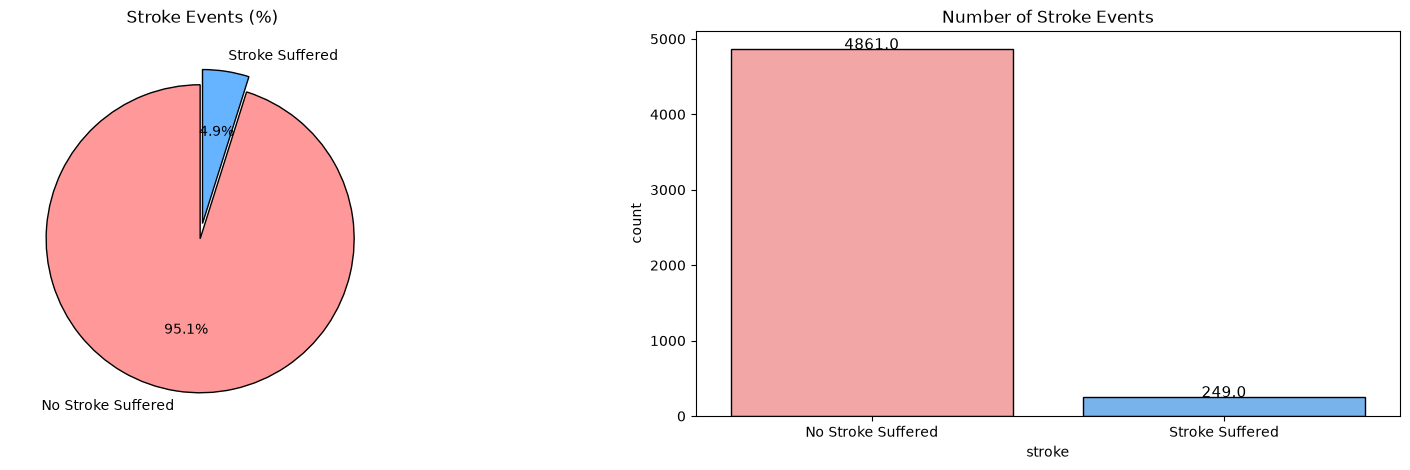

In [6]:
colors = ['#ff9999', '#66b3ff']

stroke_counts = df['stroke'].value_counts()
circle = [count / sum(stroke_counts) * 100 for count in stroke_counts]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(20, 5))

axes[0].pie(
    circle, labels=['No Stroke Suffered', 'Stroke Suffered'],
    autopct='%1.1f%%', startangle=90, explode=(0.1, 0), colors=colors,
    wedgeprops={'edgecolor': 'black', 'linewidth': 1, 'antialiased': True}
)
axes[0].set_title('Stroke Events (%)')

ax = sns.countplot(
    x='stroke', data=df, palette=colors, edgecolor='black', ax=axes[1]
)
for rect in ax.patches:
    height = rect.get_height()
    ax.text(
        rect.get_x() + rect.get_width() / 2, height + 2, height,
        ha='center', fontsize=11
    )
ax.set_xticklabels(['No Stroke Suffered', 'Stroke Suffered'])
ax.set_title('Number of Stroke Events')

plt.show()

- The dataset is unbalanced -> 19 : 1 ratio is observed (No Stroke : Stroke)
- Heavy bias towards cases of No Stroke

## V. Distribution of numerical fatures & numerical features vs '**stroke**'

In [7]:
df.drop(columns = ['id'],inplace = True)

discrete_features = []
col = list(df.columns)
for i in col:
    if len(df[i].unique()) > 6:
        discrete_features.append(i)

<Axes: xlabel='age', ylabel='Count'>

Text(0.5, 1.0, 'Distribution: age')

<Axes: xlabel='avg_glucose_level', ylabel='Count'>

Text(0.5, 1.0, 'Distribution: avg_glucose_level')

<Axes: xlabel='bmi', ylabel='Count'>

Text(0.5, 1.0, 'Distribution: bmi')

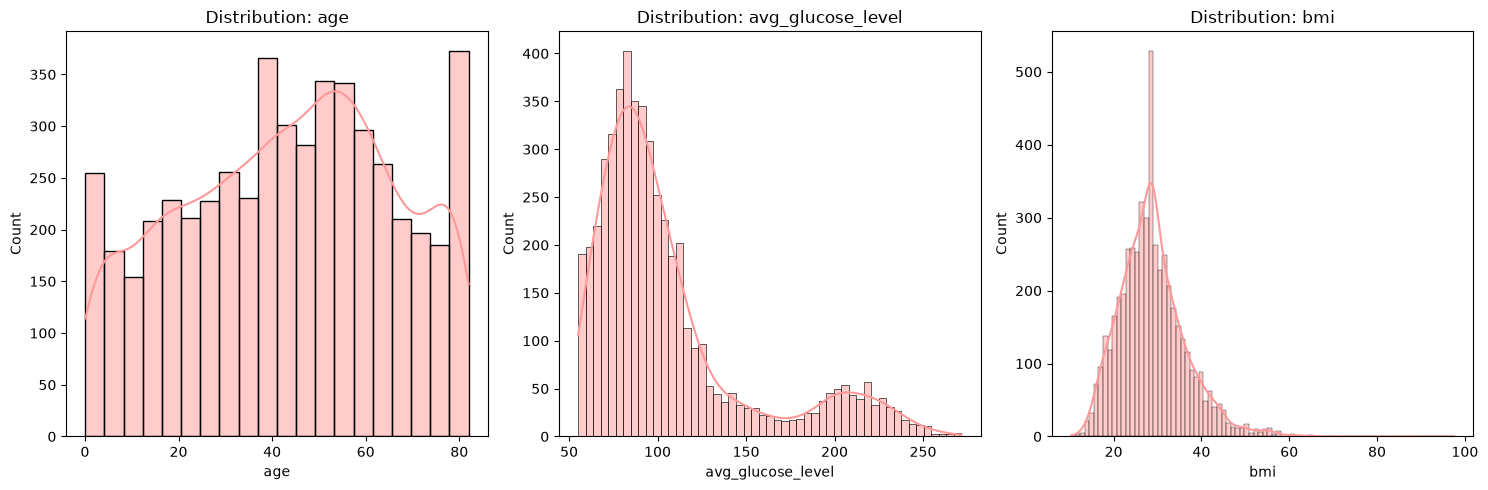

In [8]:
fig, axes = plt.subplots(nrows=1, ncols=len(discrete_features),
                         figsize=(15, 5))

for i, feature in enumerate(discrete_features):
    sns.histplot(df[feature], color=colors[0], ax=axes[i], kde=True)
    axes[i].set_title(f'Distribution: {feature}')

plt.tight_layout()
plt.show()

- age has a peak at 52, the distribution is unclear but it could be normal
- avg_glucose_level is bimodal with peaks at: 100 & 200
- bmi is normally distributed but not perfectly

<Axes: xlabel='age_group', ylabel='count'>

Text(0.5, 1.0, 'age_group vs stroke')

<Axes: xlabel='avg_glucose_level_group', ylabel='count'>

Text(0.5, 1.0, 'avg_glucose_level_group vs stroke')

<Axes: xlabel='bmi_group', ylabel='count'>

Text(0.5, 1.0, 'bmi_group vs stroke')

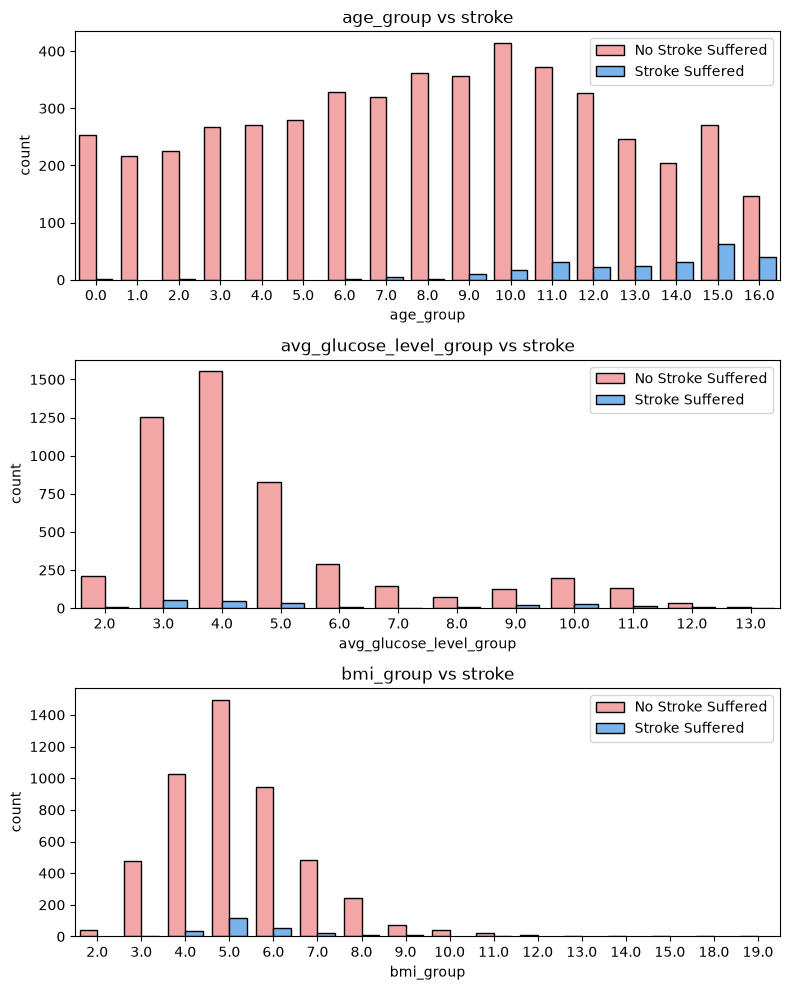

In [9]:
df['age_group'] = df['age'] // 5
df['avg_glucose_level_group'] = df['avg_glucose_level'] // 20
df['bmi_group'] = df['bmi'] // 5

fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(8, 10))
group_numerical_features = [
    f'{feature}_group' for feature in ['age', 'avg_glucose_level', 'bmi']
]

for i, feature in enumerate(group_numerical_features):
    sns.countplot(
        x=feature, data=df, hue='stroke', palette=colors,
        edgecolor='black', ax=axes[i]
    )
    axes[i].legend(
        ['No Stroke Suffered', 'Stroke Suffered'], loc='upper right'
    )
    axes[i].set_title(f'{feature} vs stroke')

plt.tight_layout()
plt.show()

- The stroke rate rises steeply with **age**: 0.2 % under 20, 2 % at 41–50, 6 % at 51–60 and 18 % above 70.
- For **avg_glucose_level** the counts show two groups (around 60–100 and 180–220). Most strokes fall in the first group only because most patients are there; the stroke **rate** is much higher in the second group (13.6 % above 180 vs 3.6 % below 100).
- For **bmi** the stroke rate is highest between 25 and 30 (7.1 %) and very low below 18.5 (0.3 %), partly because low BMI is common among children.

## VI. Distribution of Categorical Features & Categorical Features vs '**stroke**'

In [10]:
col = list(df.columns)
categorical_features = []
for i in col:
    if len(df[i].unique()) <= 6:
        categorical_features.append(i)

print('Categorical Features:', ' ,' .join(categorical_features))

Categorical Features: gender ,hypertension ,heart_disease ,ever_married ,work_type ,Residence_type ,smoking_status ,stroke


In [11]:
le = LabelEncoder()
text_data_features = [
    'gender', 'ever_married', 'work_type', 'Residence_type',
    'smoking_status'
]
l3 = []
l4 = []

print('Label Encoder Transformation')
for feature in tqdm(text_data_features):
    df[feature] = le.fit_transform(df[feature])
    l3.append(list(df[feature].unique()))
    l4.append(list(le.inverse_transform(df[feature].unique())))
    print(
        f"{feature} : {df[feature].unique()} = "
        f"{le.inverse_transform(df[feature].unique())}"
    )

Label Encoder Transformation


  0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 5/5 [00:00<00:00, 278.02it/s]

gender : [1 0 2] = ['Male' 'Female' 'Other']
ever_married : [1 0] = ['Yes' 'No']
work_type : [2 3 0 4 1] = ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
Residence_type : [1 0] = ['Urban' 'Rural']
smoking_status : [1 2 3 0] = ['formerly smoked' 'never smoked' 'smokes' 'Unknown']


In [12]:
tf1 = {}
for i in range(len(text_data_features)):
    tf1[text_data_features[i]] = {}
    for j,k in zip(l3[i],l4[i]):
        tf1[text_data_features[i]][j] = k

tf1['hypertension'] = {0 : 'No Hypertension', 1 : 'Hypertension'}
tf1['heart_disease'] = {0 : 'No Heart Disease', 1 : 'Heart Disease'}
tf1

{'gender': {np.int64(1): 'Male', np.int64(0): 'Female', np.int64(2): 'Other'},
 'ever_married': {np.int64(1): 'Yes', np.int64(0): 'No'},
 'work_type': {np.int64(2): 'Private',
  np.int64(3): 'Self-employed',
  np.int64(0): 'Govt_job',
  np.int64(4): 'children',
  np.int64(1): 'Never_worked'},
 'Residence_type': {np.int64(1): 'Urban', np.int64(0): 'Rural'},
 'smoking_status': {np.int64(1): 'formerly smoked',
  np.int64(2): 'never smoked',
  np.int64(3): 'smokes',
  np.int64(0): 'Unknown'},
 'hypertension': {0: 'No Hypertension', 1: 'Hypertension'},
 'heart_disease': {0: 'No Heart Disease', 1: 'Heart Disease'}}

<Axes: xlabel='gender'>

Text(0.5, 1.0, 'Distribution: gender')

Text(0.5, 0, '')

Text(0, 0.5, '% of patients')

<Axes: xlabel='hypertension'>

Text(0.5, 1.0, 'Distribution: hypertension')

... (22 outputs left out)

<Axes: xlabel='stroke'>

Text(0.5, 1.0, 'Distribution: stroke')

Text(0.5, 0, '')

Text(0, 0.5, '% of patients')

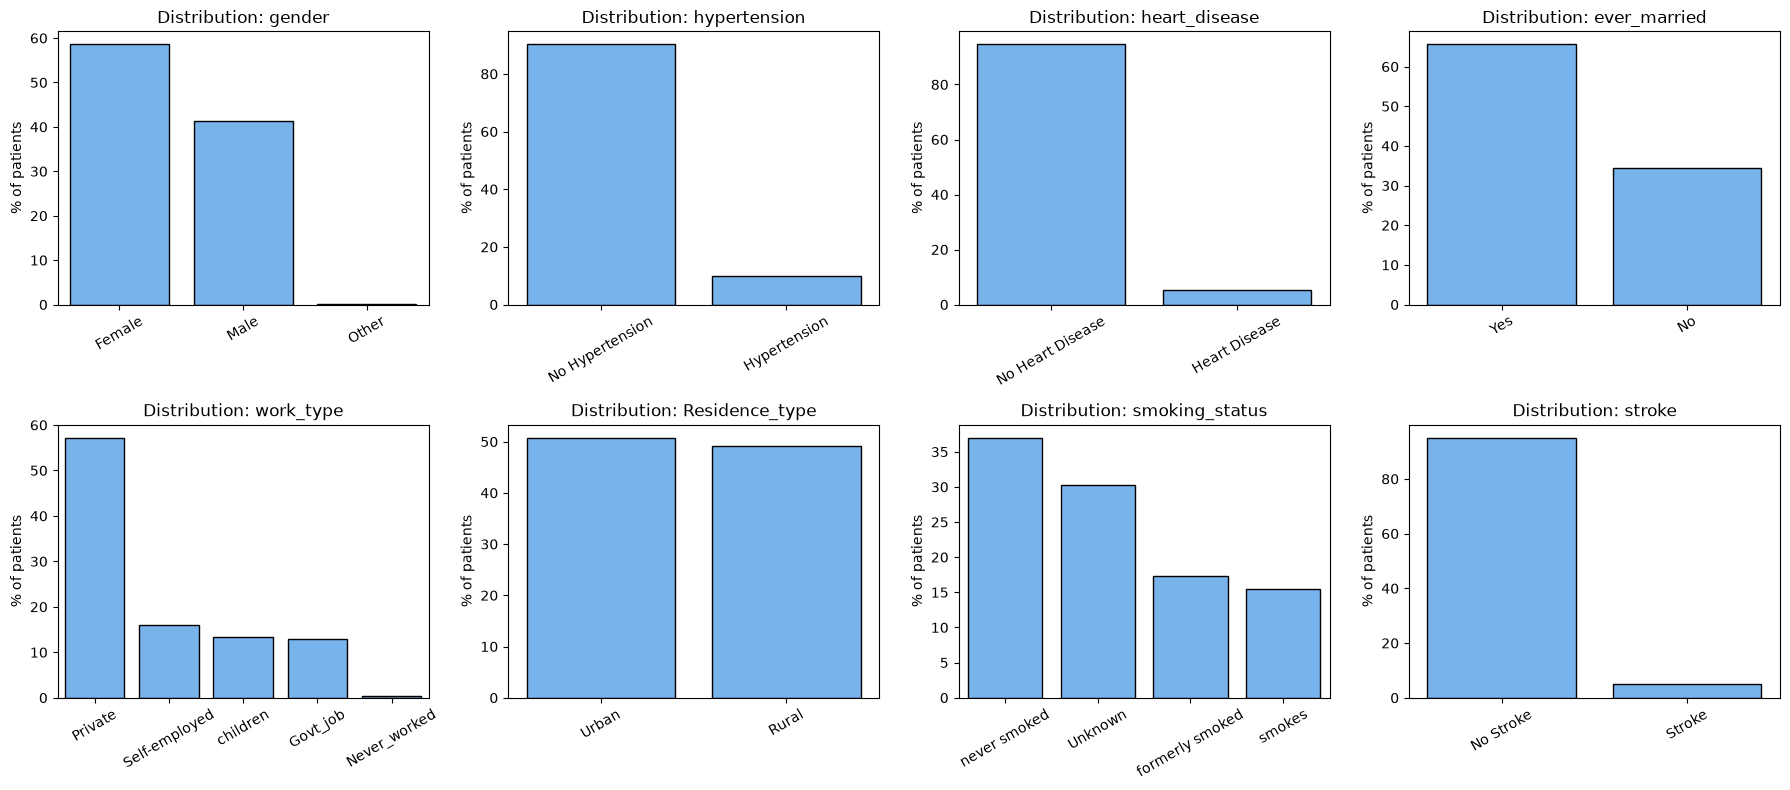

In [13]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(18, 8))
for ax, feature in zip(axes.flat, categorical_features):
    labels = tf1.get(feature, {0: 'No Stroke', 1: 'Stroke'})
    shares = df[feature].map(labels).value_counts(normalize=True).mul(100)
    sns.barplot(x=shares.index, y=shares.values, color=colors[1], edgecolor='black', ax=ax)
    ax.set_title(f'Distribution: {feature}')
    ax.set_xlabel('')
    ax.set_ylabel('% of patients')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

- Most patients have no hypertension (90 %) and no heart disease (95 %).
- 59 % are female, 66 % have been married and 57 % work in the private sector.
- Smoking status is unknown for 30 % of patients, which limits what this feature can tell us.
- Residence type is split almost evenly between urban and rural.

<Axes: >

Text(-0.2, 2855.0, '2853.0')

Text(0.8, 2009.0, '2007.0')

Text(1.8, 3.0, '1.0')

Text(0.20000000000000007, 143.0, '141.0')

Text(1.2000000000000002, 110.0, '108.0')

... (49 outputs left out)

Text(3.2, 67.0, '65.0')

Text(4.2, 4.0, '2.0')

[Text(0, 0, 'Govt_job'),
 Text(1, 0, 'Never_worked'),
 Text(2, 0, 'Private'),
 Text(3, 0, 'Self-employed'),
 Text(4, 0, 'children')]

Text(0.5, 1.0, 'work_type vs stroke')

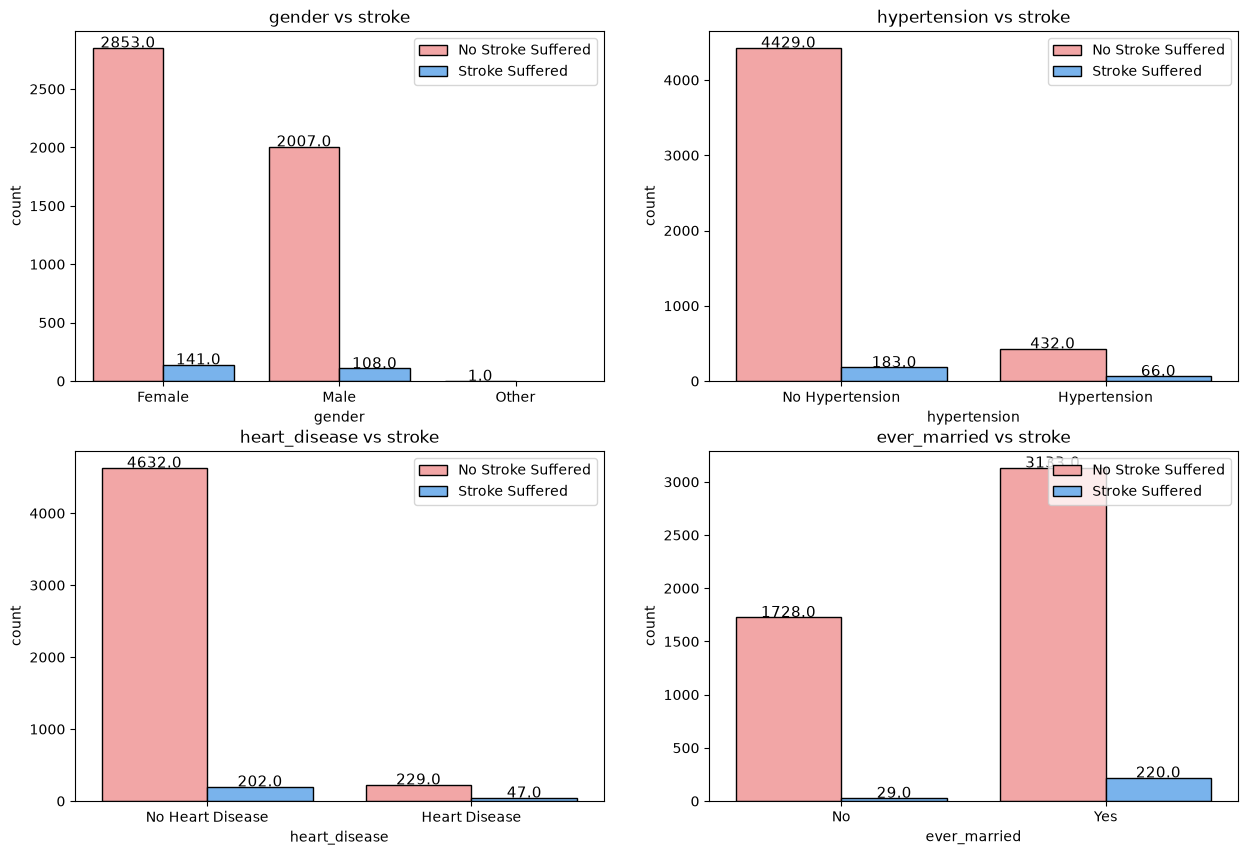

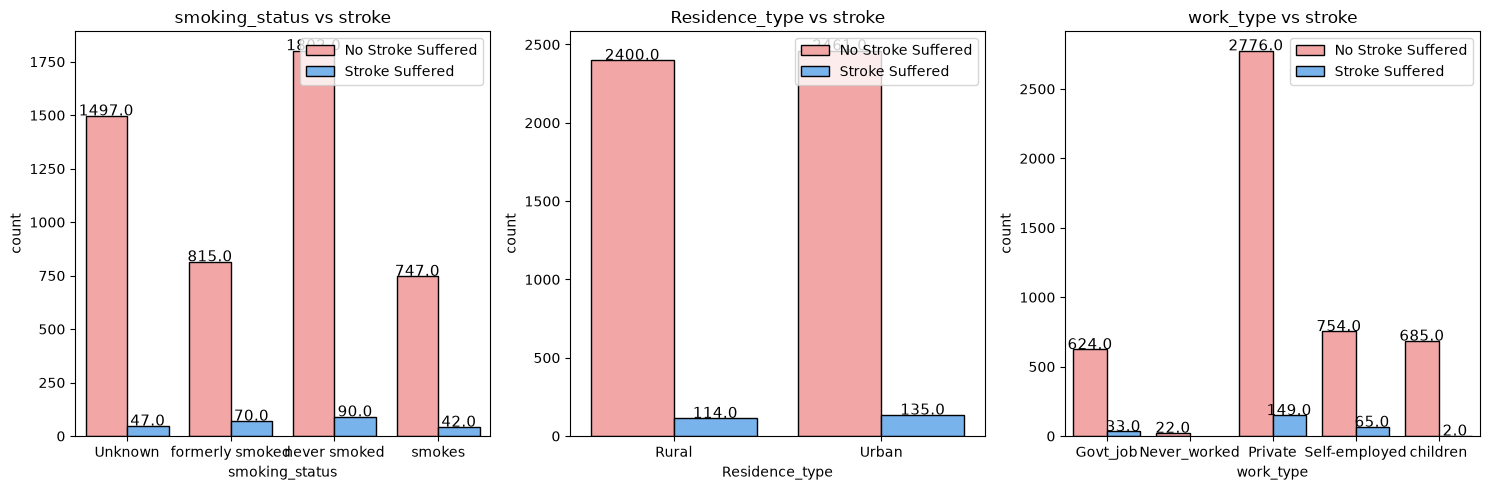

In [14]:
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    ax = sns.countplot(
        x=categorical_features[i], data=df, hue="stroke",
        palette=colors, edgecolor='black'
    )
    for rect in ax.patches:
        height = rect.get_height()
        if height > 0:
            ax.text(
                rect.get_x() + rect.get_width() / 2, height + 2,
                height, ha='center', fontsize=11
            )
    ax.set_xticklabels([
        tf1[categorical_features[i]][j] for j in sorted(
            df[categorical_features[i]].unique()
        )]
    )
    plt.legend(
        ['No Stroke Suffered', 'Stroke Suffered'], loc='upper right'
    )
    plt.title(f'{categorical_features[i]} vs stroke')

categorical_features.remove('stroke')

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
for i in range(-1, -4, -1):
    plt.subplot(1, 3, -i)
    ax = sns.countplot(
        x=categorical_features[i], data=df, hue="stroke",
        palette=colors, edgecolor='black'
    )
    for rect in ax.patches:
        height = rect.get_height()
        if height > 0:
            ax.text(
                rect.get_x() + rect.get_width() / 2, height + 2,
                height, ha='center', fontsize=11
            )
    ax.set_xticklabels([
        tf1[categorical_features[i]][j] for j in sorted(
            df[categorical_features[i]].unique()
        )]
    )
    plt.legend(
        ['No Stroke Suffered', 'Stroke Suffered'], loc='upper right'
    )
    plt.title(f'{categorical_features[i]} vs stroke')

plt.tight_layout()
plt.show()

In [15]:
rates = []
for feature in categorical_features:
    if feature == 'stroke':
        continue
    by_level = df.groupby(df[feature].map(tf1[feature]))['stroke'].agg(['size', 'mean'])
    for level, row in by_level.iterrows():
        rates.append({'feature': feature, 'value': level, 'patients': int(row['size']),
                      'stroke rate (%)': round(100 * row['mean'], 1)})
pd.DataFrame(rates).set_index(['feature', 'value'])

patients  stroke rate (%)
feature        value                                      
gender         Female                2994             4.70
               Male                  2115             5.10
               Other                    1             0.00
hypertension   Hypertension           498            13.30
               No Hypertension       4612             4.00
heart_disease  Heart Disease          276            17.00
               No Heart Disease      4834             4.20
ever_married   No                    1757             1.70
               Yes                   3353             6.60
work_type      Govt_job               657             5.00
               Never_worked            22             0.00
               Private               2925             5.10
               Self-employed          819             7.90
               children               687             0.30
Residence_type Rural                 2514             4.50
               Urban                 2596             5.20
smoking_status Unknown               1544             3.00
               formerly smoked        885             7.90
               never smoked          1892             4.80
               smokes                 789             5.30

The count plots show how many strokes each group has, but the groups differ a lot in size, so the **stroke rate** in the table above is what matters:
- **Hypertension** (13.3 % vs 4.0 %) and **heart disease** (17.0 % vs 4.2 %) roughly triple the stroke rate, in line with medical knowledge. In the count plots most strokes appear in the "no" groups only because those groups are much larger.
- **Gender** makes little difference (4.7 % for women, 5.1 % for men); there are more stroke cases among women simply because there are more women in the data.
- People who **have been married** have a higher rate (6.6 % vs 1.7 %), but they are also much older on average (54 vs 22 years), so this mostly reflects age.
- **Former smokers** have the highest rate (7.9 %). The "Unknown" group has a low rate (3.0 %), partly because 40 % of it are children.
- Among work types, **self-employed** people have the highest rate (7.9 %), again an older group; children have almost none (0.3 %).
- **Residence type** makes little difference (5.2 % urban vs 4.5 % rural).

## VII. Creating a correlation matrix.

Given the dataset includes both continuous variables (like age, avg_glucose_level, bmi) and binary variables (like hypertension, heart_disease, stroke), Spearman’s correlation might be more appropriate. It can capture non-linear relationships and is less sensitive to outliers, which is useful in medical datasets where such anomalies might be present.

<Figure size 1200x800 with 0 Axes>

<Axes: >

Text(0.5, 1.0, 'Spearman Correlation Matrix')

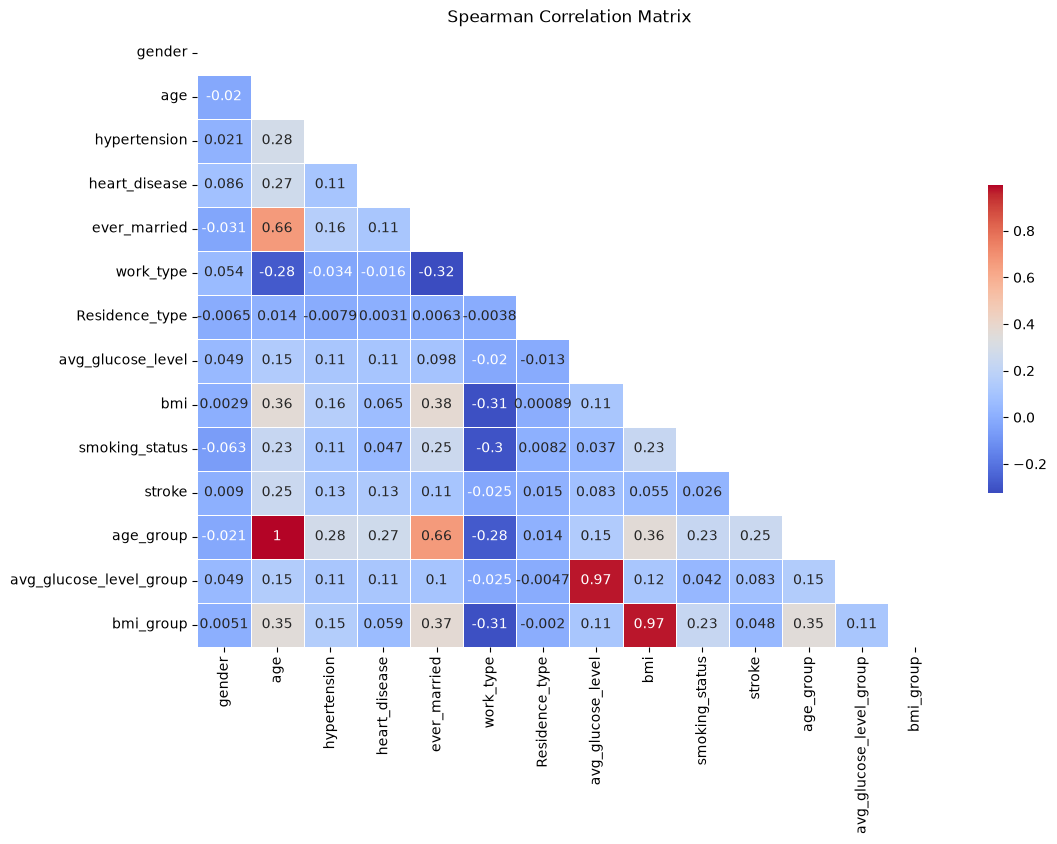

In [16]:
plt.figure(figsize=(12, 8))
numeric_df = df.select_dtypes(include=[np.number])
correlation_matrix = numeric_df.corr(method='spearman')

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

sns.heatmap(
    correlation_matrix, mask=mask, annot=True, cmap='coolwarm',
    linewidths=0.5, cbar_kws={"shrink": 0.5}
)
plt.title('Spearman Correlation Matrix')
plt.show()

- **age**, **heart_disease**, **avg_glucose_level**, **hypertension** & **ever_married** display some kind of positive correlation. Overall, all the features have a value very close to 0, displaying neutral correlation with **stroke**.

## VIII. Checking for outliers using boxplots

Focusing only on the relevant numerical features

<Figure size 1000x500 with 0 Axes>

<Axes: >

<Axes: ylabel='age'>

Text(0.5, 1.0, 'Boxplot of age')

<Axes: >

<Axes: ylabel='avg_glucose_level'>

Text(0.5, 1.0, 'Boxplot of avg_glucose_level')

<Axes: >

<Axes: ylabel='bmi'>

Text(0.5, 1.0, 'Boxplot of bmi')

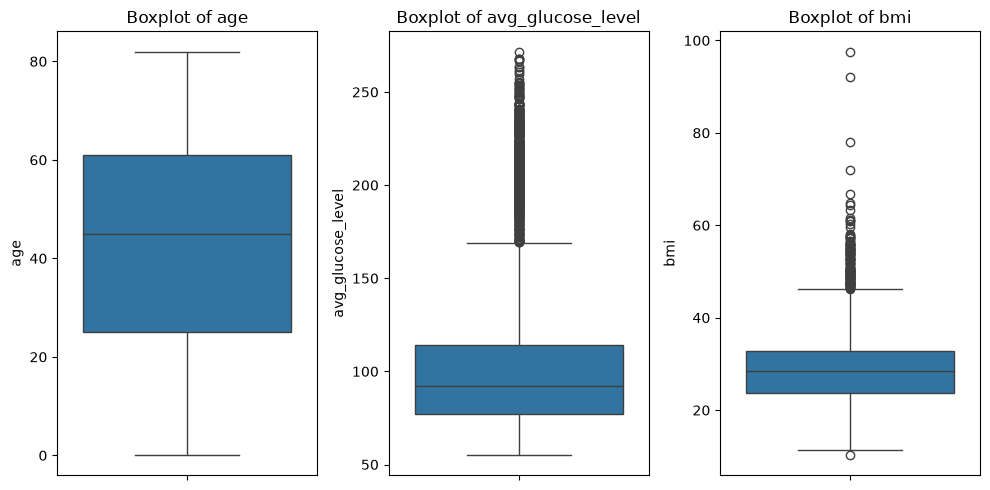

In [17]:
numeric_columns = ['age', 'avg_glucose_level', 'bmi']

plt.figure(figsize=(10, 5))
for i, column in enumerate(numeric_columns, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(df[column])
    plt.title(f'Boxplot of {column}')
plt.tight_layout()
plt.show()

It seems that avg_glucose_level and bmi have several outliers, indicating potential anomalies.

## IX. Detecting anomalies using Z-score

For **avg_glucose_level** & **bmi**

In [18]:
features_to_check = ['avg_glucose_level', 'bmi']
z_scores = np.abs(stats.zscore(df[features_to_check]))
anomalies = np.where(z_scores > 3)
print("\nAnomalies detected using Z-score for avg_glucose_level and bmi:")
print(anomalies)


Anomalies detected using Z-score for avg_glucose_level and bmi:
(array([  33,   45,  113,  122,  123,  135,  193,  196,  220,  243,  256,
        258,  270,  303,  330,  333,  358,  386,  430,  466,  544,  552,
        637,  662,  672,  715,  755,  761,  785,  805,  928, 1061, 1067,
       1070, 1077, 1113, 1207, 1304, 1322, 1384, 1436, 1453, 1529, 1532,
       1559, 1564, 1584, 1595, 1626, 1660, 1898, 2071, 2081, 2128, 2136,
       2182, 2203, 2293, 2330, 2441, 2462, 2494, 2545, 2555, 2567, 2633,
       2693, 2751, 2764, 2815, 2840, 3060, 3088, 3215, 3243, 3342, 3393,
       3508, 3588, 3606, 3688, 3702, 3825, 3909, 3931, 3980, 4048, 4154,
       4188, 4209, 4225, 4249, 4283, 4351, 4356, 4407, 4447, 4457, 4470,
       4475, 4598, 4711, 4838, 4906, 4909, 4952, 4983, 5034]), array([0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0,
       1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1

Unclear how the anomalies should be dealt with as that could have a negative impact for model predicting.

# Statistical inference

Target population - all the patients whose data is recorded in the dataset, which consists of 5,110 entries.

## Hypotheses testing


A. **H0:** the stroke rate is the same for people older than 50 and for people aged 50 or younger. **H1:** the stroke rate differs between the two groups.

In [19]:
df['age_group'] = np.where(
    df['age'] > 50, 'Older than 50', '50 and younger'
)

contingency_table = pd.crosstab(
    df['age_group'], df['stroke']
)

chi2_stat, p, dof, expected = chi2_test(
    contingency_table
)

stroke_counts = df.groupby(
    'age_group'
)['stroke'].sum()

total_counts = df['age_group'].value_counts().reindex(stroke_counts.index)  # same order as stroke_counts
proportions = stroke_counts / total_counts

conf_intervals = sm.stats.proportion_confint(
    stroke_counts, total_counts, alpha=0.05
)

print("Contingency Table:")
print(contingency_table)
print("\nChi-square Test:")
print(f"Chi2: {chi2_stat:.2f}, p-value: {p:.2e}")
print("\nProportions and Confidence Intervals:")
for group in proportions.index:
    print(
        f"{group}: Proportion = {proportions[group]:.3f}, "
        f"95% CI = ({conf_intervals[0][group]:.3f}, "
        f"{conf_intervals[1][group]:.3f})"
    )

Contingency Table:
stroke             0    1
age_group                
50 and younger  2960   23
Older than 50   1901  226

Chi-square Test:
Chi2: 257.99, p-value: 4.70e-58

Proportions and Confidence Intervals:
50 and younger: Proportion = 0.008, 95% CI = (0.005, 0.011)
Older than 50: Proportion = 0.106, 95% CI = (0.093, 0.119)


- Among people aged **50 or younger**, **23 of 2,983** had a stroke (0.8 %, 95 % CI 0.5–1.1 %).
- Among people **older than 50**, **226 of 2,127** had a stroke (10.6 %, 95 % CI 9.3–11.9 %).

Chi-square test: χ² ≈ 258, p ≈ 4.7 × 10⁻⁵⁸. We reject H0: the stroke rate is much higher for people older than 50, and the confidence intervals do not overlap.

B. **H0:** the stroke rate is the same for overweight people (BMI > 25) and for people with BMI ≤ 25. **H1:** the stroke rate differs between the two groups.

In [20]:
df['bmi_category'] = np.where(
    df['bmi'] > 25, 'Overweight', 'Normal weight'
)

contingency_table = pd.crosstab(
    df['bmi_category'], df['stroke']
)

chi2_stat, p, dof, expected = chi2_test(
    contingency_table
)

stroke_counts = df.groupby(
    'bmi_category'
)['stroke'].sum()

total_counts = df['bmi_category'].value_counts().reindex(stroke_counts.index)  # same order as stroke_counts
proportions = stroke_counts / total_counts

conf_intervals = sm.stats.proportion_confint(
    stroke_counts, total_counts, alpha=0.05
)

print("Contingency Table:")
print(contingency_table)
print("\nChi-square Test:")
print(f"Chi2: {chi2_stat:.2f}, p-value: {p:.2e}")
print("\nProportions and Confidence Intervals:")
for group in proportions.index:
    print(
        f"{group}: Proportion = {proportions[group]:.3f}, "
        f"95% CI = ({conf_intervals[0][group]:.3f}, "
        f"{conf_intervals[1][group]:.3f})"
    )

Contingency Table:
stroke            0    1
bmi_category            
Normal weight  1569   38
Overweight     3292  211

Chi-square Test:
Chi2: 31.03, p-value: 2.54e-08

Proportions and Confidence Intervals:
Normal weight: Proportion = 0.024, 95% CI = (0.016, 0.031)
Overweight: Proportion = 0.060, 95% CI = (0.052, 0.068)


- With **BMI ≤ 25**, **38 of 1,607** had a stroke (2.4 %, 95 % CI 1.6–3.1 %).
- With **BMI > 25**, **211 of 3,503** had a stroke (6.0 %, 95 % CI 5.2–6.8 %).

Chi-square test: χ² ≈ 31.0, p ≈ 2.5 × 10⁻⁸. We reject H0: overweight people have a higher stroke rate. The test shows an association, not a cause; part of the difference is likely due to age, since BMI is lower in children and young adults. The 201 missing BMI values were filled with the mean (28.9), so they count as overweight.

# Feature selection

Understanding the importance of different features

- Mutual Information
- Chi-Squared
- ANOVA

In [21]:
data = pd.read_csv(DATA_PATH)

data['bmi'] = data['bmi'].fillna(data['bmi'].mean())

le = LabelEncoder()
text_data_features = [
    'gender', 'ever_married', 'work_type',
    'Residence_type', 'smoking_status'
]
l3 = []
l4 = []

print('Label Encoder Transformation')
for feature in tqdm(text_data_features):
    data[feature] = le.fit_transform(data[feature])
    l3.append(list(data[feature].unique()))
    l4.append(list(le.inverse_transform(data[feature].unique())))
    print(
        f"{feature} : {data[feature].unique()} = "
        f"{le.inverse_transform(data[feature].unique())}"
    )

tf1 = {}
for i in range(len(text_data_features)):
    tf1[text_data_features[i]] = {}
    for j, k in zip(l3[i], l4[i]):
        tf1[text_data_features[i]][j] = k

tf1['hypertension'] = {0: 'No Hypertension', 1: 'Hypertension'}
tf1['heart_disease'] = {0: 'No Heart Disease', 1: 'Heart Disease'}

print(tf1)

Label Encoder Transformation


  0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 5/5 [00:00<00:00, 1181.43it/s]

gender : [1 0 2] = ['Male' 'Female' 'Other']
ever_married : [1 0] = ['Yes' 'No']
work_type : [2 3 0 4 1] = ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
Residence_type : [1 0] = ['Urban' 'Rural']
smoking_status : [1 2 3 0] = ['formerly smoked' 'never smoked' 'smokes' 'Unknown']
{'gender': {np.int64(1): 'Male', np.int64(0): 'Female', np.int64(2): 'Other'}, 'ever_married': {np.int64(1): 'Yes', np.int64(0): 'No'}, 'work_type': {np.int64(2): 'Private', np.int64(3): 'Self-employed', np.int64(0): 'Govt_job', np.int64(4): 'children', np.int64(1): 'Never_worked'}, 'Residence_type': {np.int64(1): 'Urban', np.int64(0): 'Rural'}, 'smoking_status': {np.int64(1): 'formerly smoked', np.int64(2): 'never smoked', np.int64(3): 'smokes', np.int64(0): 'Unknown'}, 'hypertension': {0: 'No Hypertension', 1: 'Hypertension'}, 'heart_disease': {0: 'No Heart Disease', 1: 'Heart Disease'}}


In [22]:
f1 = data.drop(columns=['id', 'stroke'])
t1 = data['stroke']
categorical_inputs = [f for f in categorical_features if f != 'stroke']
Counter(t1)

Counter({0: 4861, 1: 249})

In [23]:
# Split before anything is learned from the data; stratified so both parts keep the real 1:19 ratio
x_train, x_test, y_train, y_test = train_test_split(
    f1, t1, test_size=0.2, stratify=t1, random_state=42
)
x_train_test = x_train.copy(deep=True)
x_train_test['stroke'] = y_train
print(f"Training set: {len(x_train)} patients ({y_train.sum()} strokes); "
      f"test set: {len(x_test)} patients ({y_test.sum()} strokes)")

Training set: 4088 patients (199 strokes); test set: 1022 patients (50 strokes)


## Mutual information: categorical features and the stroke feature

<Axes: >

<Axes: >

Text(0.5, 1.0, 'Categorical features: training split only')

<Axes: >

<Axes: >

Text(0.5, 1.0, 'Categorical features: whole dataset (includes test data)')

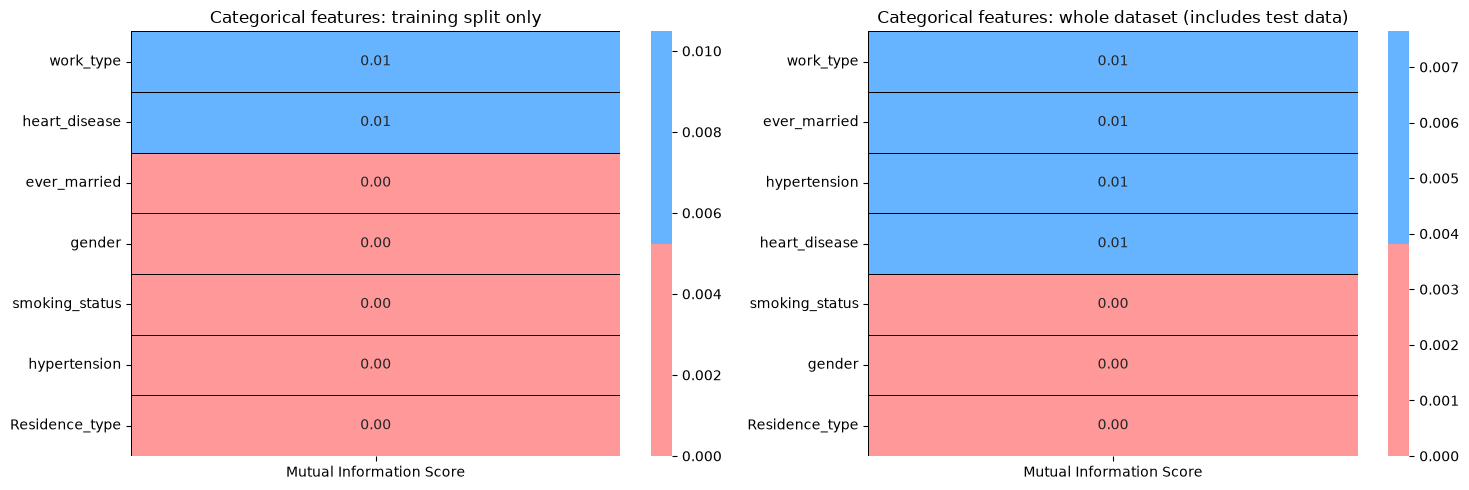

In [24]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

plt.subplot(1, 2, 1)
features = x_train.loc[:, categorical_inputs]
target = pd.DataFrame(y_train)

best_features = SelectKBest(score_func=mutual_info_classif, k='all')
fit = best_features.fit(features, target)

feature_scores = pd.DataFrame(
    data=fit.scores_,
    index=list(features.columns),
    columns=['Mutual Information Score']
)
sns.heatmap(
    feature_scores.sort_values(
        ascending=False, by='Mutual Information Score'
    ),
    annot=True, cmap=colors, linewidths=0.4,
    linecolor='black', fmt='.2f'
)
plt.title('Categorical features: training split only')

plt.subplot(1, 2, 2)
features = data.loc[:, categorical_inputs]
target = data.loc[:, 'stroke']

best_features = SelectKBest(score_func=mutual_info_classif, k='all')
fit = best_features.fit(features, target)

feature_scores = pd.DataFrame(
    data=fit.scores_,
    index=list(features.columns),
    columns=['Mutual Information Score']
)
sns.heatmap(
    feature_scores.sort_values(
        ascending=False, by='Mutual Information Score'
    ),
    annot=True, cmap=colors, linewidths=0.4,
    linecolor='black', fmt='.2f'
)
plt.title('Categorical features: whole dataset (includes test data)')

plt.tight_layout()
plt.show()

In each pair of plots, the left one uses the **training split only**; the right one uses the whole dataset, including the test set, and is shown only for comparison (feature choices based on it would leak test information).

Mutual information between the categorical features and stroke is very low for all of them (≤ 0.01). With a 1:19 class imbalance, mutual information with a binary target is small by nature, so on its own this is not a reason to drop features.

## Chi-squared: : categorical features and the stroke feature

<Axes: >

<Axes: >

Text(0.5, 1.0, 'Categorical features: training split only')

<Axes: >

<Axes: >

Text(0.5, 1.0, 'Categorical features: whole dataset (includes test data)')

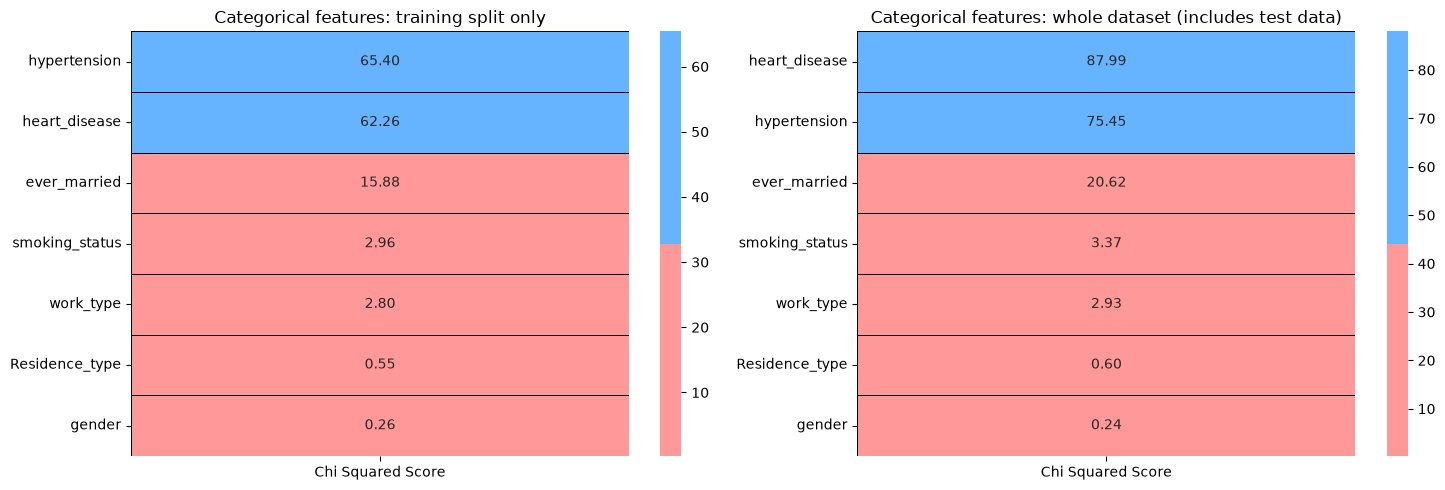

In [25]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

plt.subplot(1, 2, 1)
features = x_train.loc[:, categorical_inputs]
target = y_train

best_features = SelectKBest(score_func=chi2, k='all')
fit = best_features.fit(features, target)

feature_scores = pd.DataFrame(
    data=fit.scores_,
    index=list(features.columns),
    columns=['Chi Squared Score']
)
sns.heatmap(
    feature_scores.sort_values(
        ascending=False, by='Chi Squared Score'
    ),
    annot=True, cmap=colors, linewidths=0.4,
    linecolor='black', fmt='.2f'
)
plt.title('Categorical features: training split only')

plt.subplot(1, 2, 2)
features = data.loc[:, categorical_inputs]
target = data.loc[:, 'stroke']

best_features = SelectKBest(score_func=chi2, k='all')
fit = best_features.fit(features, target)

feature_scores = pd.DataFrame(
    data=fit.scores_,
    index=list(features.columns),
    columns=['Chi Squared Score']
)
sns.heatmap(
    feature_scores.sort_values(
        ascending=False, by='Chi Squared Score'
    ),
    annot=True, cmap=colors, linewidths=0.4,
    linecolor='black', fmt='.2f'
)
plt.title('Categorical features: whole dataset (includes test data)')

plt.tight_layout()
plt.show()

On the training split, **hypertension** (≈ 65) and **heart_disease** (≈ 62) have by far the highest chi-squared scores, followed by **ever_married** (≈ 16). Gender, Residence_type, work_type and smoking_status score below 5. Chi-squared on label-encoded multi-category features (work_type, smoking_status) is only a rough guide, so all features are kept and the models decide how much to use them.

## ANOVA: numerical feature and stroke feature

<Axes: >

<Axes: >

Text(0.5, 1.0, 'Numerical features: training split only')

<Axes: >

<Axes: >

Text(0.5, 1.0, 'Numerical features: whole dataset (includes test data)')

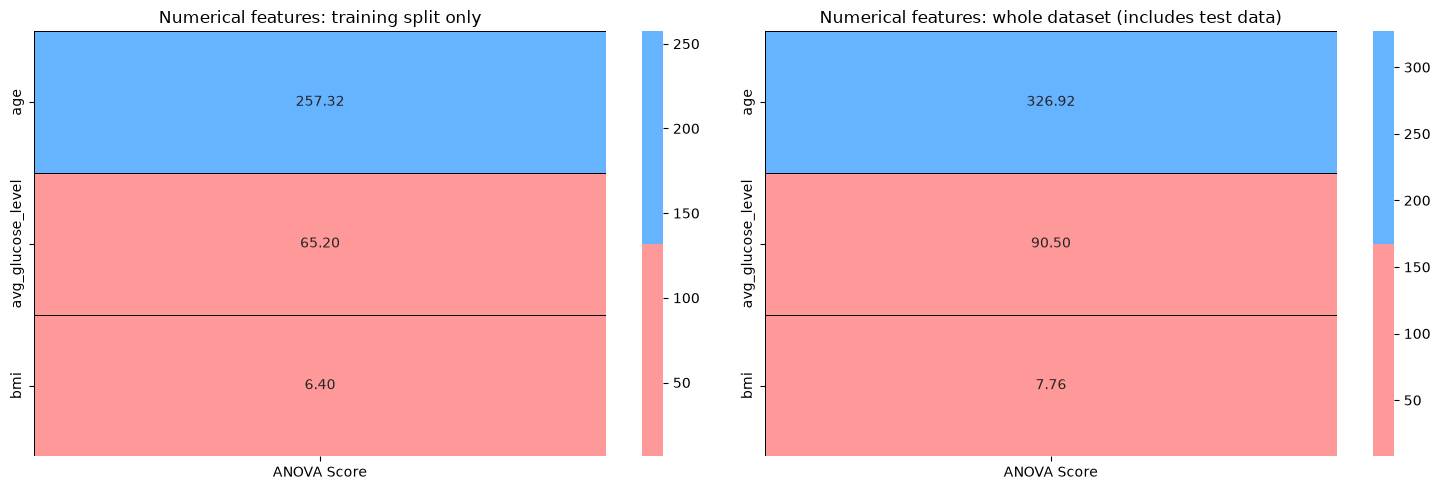

In [26]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

plt.subplot(1, 2, 1)
features = x_train.loc[:, discrete_features]
target = y_train

best_features = SelectKBest(score_func=f_classif, k='all')
fit = best_features.fit(features, target)

feature_scores = pd.DataFrame(
    data=fit.scores_,
    index=list(features.columns),
    columns=['ANOVA Score']
)
sns.heatmap(
    feature_scores.sort_values(
        ascending=False, by='ANOVA Score'
    ),
    annot=True, cmap=colors, linewidths=0.4,
    linecolor='black', fmt='.2f'
)
plt.title('Numerical features: training split only')

plt.subplot(1, 2, 2)
features = data.loc[:, discrete_features]
target = data.loc[:, 'stroke']

best_features = SelectKBest(score_func=f_classif, k='all')
fit = best_features.fit(features, target)

feature_scores = pd.DataFrame(
    data=fit.scores_,
    index=list(features.columns),
    columns=['ANOVA Score']
)
sns.heatmap(
    feature_scores.sort_values(
        ascending=False, by='ANOVA Score'
    ),
    annot=True, cmap=colors, linewidths=0.4,
    linecolor='black', fmt='.2f'
)
plt.title('Numerical features: whole dataset (includes test data)')

plt.tight_layout()
plt.show()

**age** has by far the highest ANOVA score (≈ 257), followed by **avg_glucose_level** (≈ 65) and **bmi** (≈ 6). All three numerical features are kept.

# Modeling

**Avoiding data leakage**
- The data is split into a training set (80 %) and a test set (20 %) **before** anything is learned from it. The split is stratified, so both parts keep the real 1:19 ratio of no stroke to stroke.
- Imputation, scaling, one-hot encoding, undersampling and SMOTE are all steps of one pipeline (`imblearn.pipeline.Pipeline`). They are fitted on the training folds only, never on validation or test data, and the test set is never resampled, so it looks like real patients.
- An earlier version of this notebook resampled the whole dataset before splitting. SMOTE then built synthetic patients from test cases and put them into the training set, and the test set itself was artificially balanced. That gave a ROC AUC of 98 %, which does not hold for real patients (see the comparison below).

**Models and tuning**
- **XGBoost** and **Random Forest**, tuned with GridSearchCV (stratified 5-fold cross-validation, ROC AUC).
- A **soft-voting ensemble** of the two best models.
- **Logistic regression** as a simple baseline.

In [27]:
data = pd.read_csv(DATA_PATH)
X = data.drop(columns=['id', 'stroke'])
y = data['stroke']

# 1. Split first. The test set keeps the real 1:19 ratio and is never resampled.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

numeric = ['age', 'avg_glucose_level', 'bmi']
binary = ['hypertension', 'heart_disease']
categorical = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
preprocess = ColumnTransformer([
    ('num', SkPipeline([('impute', SimpleImputer(strategy='median')),
                        ('scale', StandardScaler())]), numeric),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical),
    ('bin', 'passthrough', binary),
])


def resampled(model):
    """Imputation, encoding, undersampling and SMOTE all sit inside the pipeline,
    so they are fitted on the training folds only, never on validation or test data."""
    return ImbPipeline([
        ('prep', preprocess),
        ('under', RandomUnderSampler(sampling_strategy=0.1, random_state=42)),
        ('over', SMOTE(sampling_strategy=1.0, random_state=42)),
        ('classifier', model),
    ])


# 2. Tune on the training set with stratified 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
param_grid_xgb = {
    'classifier__learning_rate': [0.01, 0.1, 0.2],
    'classifier__max_depth': [3, 5, 7],
    'classifier__n_estimators': [100, 500, 1000]
}
param_grid_rf = {
    'classifier__n_estimators': [100, 500, 1000],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5, 10]
}
grid_search_xgb = GridSearchCV(resampled(XGBClassifier(random_state=42)), param_grid_xgb,
                               cv=cv, scoring='roc_auc', n_jobs=-1)
grid_search_rf = GridSearchCV(resampled(RandomForestClassifier(random_state=42)), param_grid_rf,
                              cv=cv, scoring='roc_auc', n_jobs=-1)
_ = grid_search_xgb.fit(X_train, y_train)
_ = grid_search_rf.fit(X_train, y_train)
print(f"Best cross-validated ROC AUC: XGBoost {grid_search_xgb.best_score_:.3f} "
      f"{grid_search_xgb.best_params_}")
print(f"Best cross-validated ROC AUC: Random Forest {grid_search_rf.best_score_:.3f} "
      f"{grid_search_rf.best_params_}")

# 3. A simple baseline and the soft-voting ensemble
logreg = resampled(LogisticRegression(max_iter=1000)).fit(X_train, y_train)
ensemble = VotingClassifier(estimators=[
    ('xgb', grid_search_xgb.best_estimator_),
    ('rf', grid_search_rf.best_estimator_)
], voting='soft')
_ = ensemble.fit(X_train, y_train)

Best cross-validated ROC AUC: XGBoost 0.821 {'classifier__learning_rate': 0.01, 'classifier__max_depth': 3, 'classifier__n_estimators': 100}
Best cross-validated ROC AUC: Random Forest 0.811 {'classifier__max_depth': 10, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 1000}


In [28]:
def evaluate(name, model):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {'model': name,
            'ROC AUC': roc_auc_score(y_test, proba),
            'PR AUC': average_precision_score(y_test, proba),
            'recall (stroke)': recall_score(y_test, pred),
            'precision (stroke)': precision_score(y_test, pred),
            'accuracy': accuracy_score(y_test, pred)}


results = pd.DataFrame([
    evaluate('Logistic regression', logreg),
    evaluate('XGBoost', grid_search_xgb.best_estimator_),
    evaluate('Random forest', grid_search_rf.best_estimator_),
    evaluate('Ensemble (XGBoost + RF)', ensemble),
]).set_index('model')
print(f"Test set: {len(y_test)} patients, {y_test.sum()} strokes "
      f"(a random guess gives ROC AUC 0.5 and PR AUC {y_test.mean():.3f})")
results.round(3)

Test set: 1022 patients, 50 strokes (a random guess gives ROC AUC 0.5 and PR AUC 0.049)


,ROC AUC,PR AUC,recall (stroke),precision (stroke),accuracy
model,,,,,
Logistic regression,0.84,0.29,0.80,0.14,0.75
XGBoost,0.82,0.19,0.84,0.12,0.69
Random forest,0.80,0.19,0.46,0.15,0.84
Ensemble (XGBoost + RF),0.82,0.21,0.74,0.15,0.78


In [29]:
proba = ensemble.predict_proba(X_test)[:, 1]
yt = y_test.to_numpy()
rng = np.random.default_rng(42)
boot = []
for _ in range(2000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].min() != yt[idx].max():
        boot.append(roc_auc_score(yt[idx], proba[idx]))
print(f"Ensemble test ROC AUC {roc_auc_score(yt, proba):.3f}, "
      f"95% bootstrap interval {np.percentile(boot, 2.5):.3f}-{np.percentile(boot, 97.5):.3f}")
print("\nClassification report at threshold 0.5:\n")
print(classification_report(y_test, (proba >= 0.5).astype(int), target_names=['No Stroke', 'Stroke']))

# For comparison: the earlier approach, resampling the whole dataset before splitting
Xp = preprocess.fit_transform(X)
Xr, yr = ImbPipeline([('under', RandomUnderSampler(sampling_strategy=0.1, random_state=42)),
                      ('over', SMOTE(sampling_strategy=1.0, random_state=42))]).fit_resample(Xp, y)
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.15, random_state=2)
leaky = clone(grid_search_xgb.best_estimator_.named_steps['classifier']).fit(Xr_tr, yr_tr)
print(f"Same XGBoost settings, resampling BEFORE the split: "
      f"ROC AUC {roc_auc_score(yr_te, leaky.predict_proba(Xr_te)[:, 1]):.3f} (inflated)")
leaky_rf = RandomForestClassifier(n_estimators=500, random_state=42).fit(Xr_tr, yr_tr)
print(f"Random Forest with unlimited depth, resampling BEFORE the split: "
      f"ROC AUC {roc_auc_score(yr_te, leaky_rf.predict_proba(Xr_te)[:, 1]):.3f} (inflated)")


Ensemble test ROC AUC 0.816, 95% bootstrap interval 0.763-0.868

Classification report at threshold 0.5:

              precision    recall  f1-score   support

   No Stroke       0.98      0.78      0.87       972
      Stroke       0.15      0.74      0.25        50

    accuracy                           0.78      1022
   macro avg       0.57      0.76      0.56      1022
weighted avg       0.94      0.78      0.84      1022

Same XGBoost settings, resampling BEFORE the split: ROC AUC 0.890 (inflated)


Random Forest with unlimited depth, resampling BEFORE the split: ROC AUC 0.984 (inflated)


**Results on the untouched test set** (1,022 patients, 50 strokes):
- **Logistic regression** is the best model (ROC AUC 0.84, PR AUC 0.29). The tuned XGBoost (0.82), Random Forest (0.80) and their ensemble (0.82) do not beat it: with only 199 strokes in the training data, a simple model generalises as well or better.
- With 50 strokes in the test set the uncertainty is large: the ensemble's 95 % bootstrap interval is 0.76–0.87.
- **Accuracy is misleading** here, because a model that always predicts "no stroke" would be 95 % accurate. At a threshold of 0.5 the ensemble finds 74 % of strokes (recall), but only 15 % of the patients it flags actually had one (precision). For screening, high recall with many false alarms can be acceptable, and the threshold can be moved to change that trade-off.
- **PR AUC** should be compared with 0.049, the share of strokes: 0.21–0.29 is 4–6 times better than chance, but far from a reliable diagnostic tool.
- **Why the earlier 98 % was wrong:** with resampling before the split, the same XGBoost settings reach 0.89 and a Random Forest with unlimited depth 0.98. Deep trees memorise the synthetic copies of test patients, so the score measures memory, not prediction.

# Conclusion

- **Age** is by far the strongest predictor: the stroke rate grows from under 1 % below 50 to 18 % above 70. **Hypertension**, **heart disease** and high **average glucose** each roughly triple the rate.
- Comparing **rates** rather than counts matters: in raw counts most strokes occur among people without hypertension or heart disease, only because those groups are much larger.
- Both hypotheses are supported: people older than 50 and people with BMI > 25 have significantly higher stroke rates (χ² tests, p < 0.001), although BMI is partly confounded with age.
- With leakage-free validation, the best model is a **logistic regression with ROC AUC 0.84** on the test set; the tuned XGBoost + Random Forest ensemble reaches 0.82 (95 % CI 0.76–0.87).
- The earlier 98 % ROC AUC came from resampling the whole dataset before splitting. With SMOTE, resampling must stay inside the training pipeline.
- The dataset is small and heavily imbalanced (249 strokes, 1:19), so these results are a learning exercise, not a clinical tool.

# Suggestions

1. **Address Data Imbalance**:
   - **Advanced Resampling Techniques**: Beyond SMOTE and RandomUnderSampler, consider using **ADASYN** or **Tomek Links** to handle data imbalance more effectively.
   - **Cost-Sensitive Learning**: Implement cost-sensitive algorithms that penalize misclassifications of the minority class more heavily.

2. **Feature Engineering**:
   - **Interaction Features**: Create new features that capture interactions between existing features, which might reveal hidden patterns.
   - **Domain-Specific Features**: Incorporate domain knowledge to engineer features that are more relevant to predicting strokes.

3. **Interpretability**:
   - **SHAP Values**: Use SHAP (SHapley Additive exPlanations) values to interpret the impact of each feature on the model's predictions.
   - **LIME**: Apply Local Interpretable Model-agnostic Explanations (LIME) to understand individual predictions.

4. **Decision Threshold and Calibration**:
   - Choose the decision threshold from the cost of a missed stroke versus a false alarm, instead of the default 0.5.
   - Check probability calibration (e.g. a reliability curve), since resampling shifts predicted probabilities upward.
